# 05 Augmentation Ablation

**Objective:** compare A-D augmentation strategies with one architecture locked.

**Success criteria:** A/B share original membership, C/D share original-plus-offline membership, online augmentation is a train argument, test is absent, and validation metrics select the final strategy.


## Setup and locked architecture

`DRY_RUN=True` validates all four experiment specs without training. An actual ablation requires a selected model from a completed candidate run.


In [1]:
# Purpose: initialize the controlled A-D augmentation comparison with architecture locked.
# Inputs: accepted candidate metadata, augmentation manifests, training config, and optional explicit run paths.
# Guard: actual runs require selected_model; dry-run fallback is validation-only and no test manifest is copied.
# Output: one ablation artifact containing fixed train/val manifests and full upstream provenance.
from pathlib import Path
import sys

BOOTSTRAP_ROOT = Path.cwd().resolve()
if BOOTSTRAP_ROOT.name == "notebooks":
    BOOTSTRAP_ROOT = BOOTSTRAP_ROOT.parent
if str(BOOTSTRAP_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOTSTRAP_ROOT))

import pandas as pd
from IPython.display import Markdown, display

from src.analysis.plot_utils import plot_metric_comparison
from src.artifacts import (
    create_run,
    find_latest_run,
    open_run,
    read_run_metadata,
    runtime_metadata,
    update_run_metadata,
    write_run_metadata,
)
from src.config import (
    find_project_root,
    get_experiment,
    load_pipeline_config,
    online_augmentation_args,
)
from src.dataset.manifests import (
    copy_manifest,
    experiment_manifest,
    manifest_sha256,
    write_ultralytics_dataset_yaml,
)
from src.training.evaluate_yolo import benchmark_model_latency
from src.training.train_yolo import (
    build_train_args,
    clean_training_intermediates,
    format_progress_event,
    rank_results,
    run_training_specs,
)

V2_ROOT = find_project_root(BOOTSTRAP_ROOT)
CONFIG = load_pipeline_config(V2_ROOT)
TRAINING_CONFIG = CONFIG["training"]
SEED = int(TRAINING_CONFIG["seed"])
SOURCE_AUGMENTATION_RUN = None
SOURCE_CANDIDATE_RUN = None
DRY_RUN = False
AUGMENTATION_RUN = (
    open_run(SOURCE_AUGMENTATION_RUN)
    if SOURCE_AUGMENTATION_RUN
    else find_latest_run(
        V2_ROOT, "augmentation-qa", "manifests/train_original_plus_offline.txt"
    )
)
CANDIDATE_RUN = (
    open_run(SOURCE_CANDIDATE_RUN)
    if SOURCE_CANDIDATE_RUN
    else find_latest_run(V2_ROOT, "candidate-models", "csv/candidate_model_results.csv")
)
candidate_metadata = read_run_metadata(CANDIDATE_RUN)
selected_model = candidate_metadata.get("selected_model")
if not selected_model and DRY_RUN:
    selected_model = TRAINING_CONFIG["candidate_models"][0]
if not selected_model:
    raise RuntimeError("A completed candidate run with selected_model is required")
RUN = create_run(V2_ROOT, "ablation", Path(str(selected_model)).stem, SEED)
for manifest_name in (
    "train_original.txt",
    "train_original_plus_offline.txt",
    "val.txt",
):
    copy_manifest(
        AUGMENTATION_RUN.manifests / manifest_name, RUN.manifests / manifest_name
    )
write_run_metadata(
    RUN,
    {
        "stage": "ablation",
        "status": "started",
        "dry_run": DRY_RUN,
        "seed": SEED,
        "selected_model": selected_model,
        "source_candidate_run": CANDIDATE_RUN.run_id,
        "source_augmentation_run": AUGMENTATION_RUN.run_id,
        "runtime": runtime_metadata(V2_ROOT),
    },
)

WindowsPath('C:/Github/smart-factory-safety-monitoring-system/ppe-detection/v2_pipeline/artifacts/20260826T030757Z_ablation_yolo12n_s42_027537d/run.yaml')

## Resolve the four controlled experiments

**Expected result:** four training specs backed by two manifests. Every dataset YAML contains train/val only; B/D alone enable online augmentation.


In [2]:
# Purpose: translate the four declarative experiments into two memberships and four train specs.
# Inputs: experiments.yaml, original/combined train manifests, fixed validation, and selected architecture.
# Guard: A/B share original, C/D share combined, only B/D enable online augmentation, and all YAMLs omit test.
# Output: four small run-local dataset YAML files and one readable strategy matrix.
original_manifest = RUN.manifests / "train_original.txt"
combined_manifest = RUN.manifests / "train_original_plus_offline.txt"
val_manifest = RUN.manifests / "val.txt"
ablation_specs = []
strategy_rows = []
for experiment_name in CONFIG["experiments"]["experiments"]:
    experiment = get_experiment(CONFIG, experiment_name)
    train_manifest = experiment_manifest(
        experiment, original_manifest, combined_manifest
    )
    dataset_yaml = write_ultralytics_dataset_yaml(
        RUN.manifests / f"dataset_{experiment_name}.yaml",
        train_manifest,
        val_manifest,
        CONFIG["classes"],
    )
    enabled = bool(experiment["online_augmentation"])
    ablation_specs.append(
        {
            "run_name": f"ablation-{experiment_name}",
            "model_name": selected_model,
            "experiment": experiment_name,
            "data_yaml": dataset_yaml,
            "online_augmentation": enabled,
            "augmentation_args": online_augmentation_args(
                CONFIG["augmentation"], enabled
            ),
        }
    )
    strategy_rows.append(
        {
            "experiment": experiment_name,
            "train_manifest": train_manifest.name,
            "online_augmentation": enabled,
            "test_available": False,
        }
    )
strategy_df = pd.DataFrame(strategy_rows)
display(strategy_df)

,experiment,train_manifest,online_augmentation,test_available
0,exp_A_original_only,train_original.txt,False,False
1,exp_B_online_aug,train_original.txt,True,False
2,exp_C_offline_aug,train_original_plus_offline.txt,False,False
3,exp_D_full_pipeline,train_original_plus_offline.txt,True,False


#### Observation

TODO after execution:

- Confirm A/B use the same manifest.
- Confirm C/D use the same manifest.
- Confirm only B/D enable online augmentation and no test path exists.


## Train or dry-run the ablation matrix

All non-augmentation settings and the selected architecture are fixed. One live panel is updated in place per epoch; raw logs are suppressed, while bounded failure excerpts do not hide successful experiments.


In [3]:
# Purpose: execute or validate the complete ablation matrix through one shared orchestration path.
# Inputs: four explicit specs and identical non-augmentation training arguments.
# Guard: suppress raw logs while architecture, seed, epochs, image size, validation data, and runtime stay fixed.
# Output: one in-place epoch panel plus concise experiment rows, with failure log tails only when needed.
base_train_args = build_train_args(TRAINING_CONFIG, "ablation_epochs")
# Reuse one live panel for all four experiments to keep notebook output bounded.
ablation_progress = display(
    Markdown("Augmentation ablation is waiting to start."),
    display_id=True,
)


def update_ablation_progress(event: dict) -> None:
    """Render one compact experiment/epoch event in the existing panel."""
    ablation_progress.update(Markdown(format_progress_event(event)))


ablation_results_df = run_training_specs(
    ablation_specs,
    RUN.models,
    base_train_args,
    dry_run=DRY_RUN,
    continue_on_error=True,
    progress_callback=update_ablation_progress,
)
display(
    ablation_results_df[
        ["experiment", "status", "online_augmentation", "error_message"]
    ]
)

**[4/4] ablation-exp_D_full_pipeline** · yolo12n.pt — **completed** | R=0.8766 | mAP50=0.9251 | mAP50-95=0.6524 | elapsed=18:29

,experiment,status,online_augmentation,error_message
0,exp_A_original_only,trained,False,
1,exp_B_online_aug,trained,True,
2,exp_C_offline_aug,trained,False,
3,exp_D_full_pipeline,trained,True,


#### Observation

TODO after execution:

- Record failed runs or unsupported settings.
- If this is a dry run, verify all four specs before enabling training.


## Benchmark validation latency and select augmentation

Use validation recall, mAP, and latency only. Test data cannot be used to change the selected experiment.


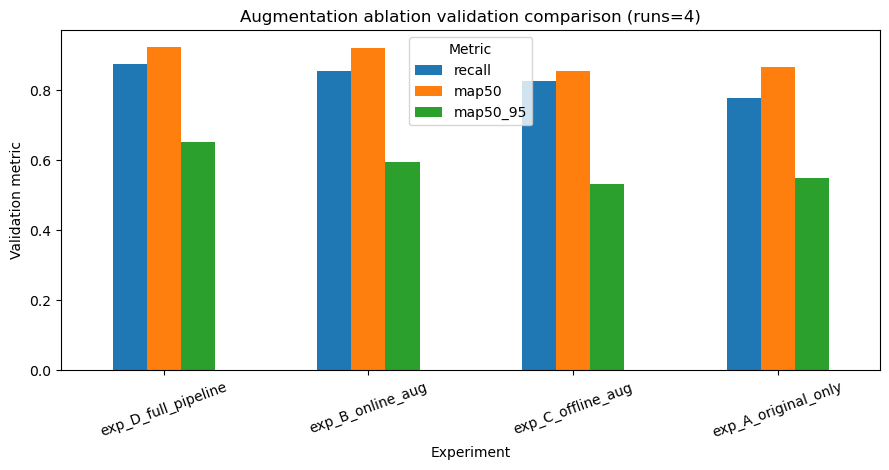

,rank,experiment,status,recall,map50,map50_95,fps
0,1,exp_D_full_pipeline,trained,0.87661,0.92512,0.65240,15.676481
1,2,exp_B_online_aug,trained,0.85538,0.91995,0.59593,15.530611
2,3,exp_C_offline_aug,trained,0.82645,0.85564,0.53307,15.661971
3,4,exp_A_original_only,trained,0.77689,0.86754,0.54826,15.372548


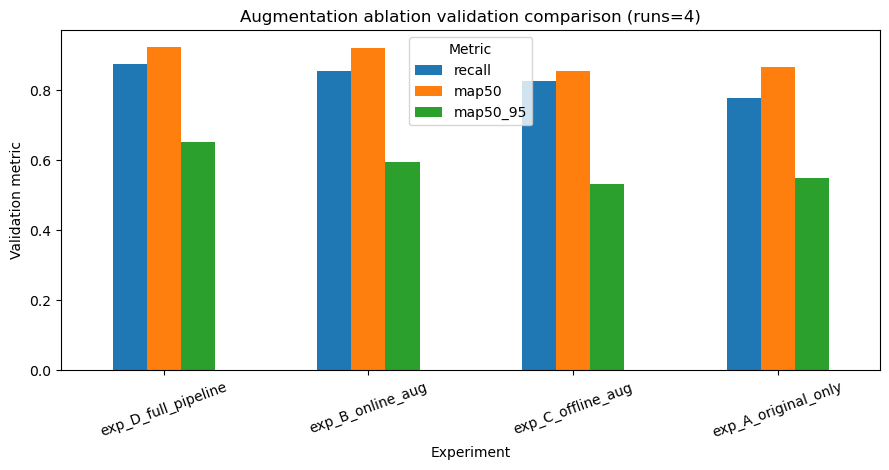

In [4]:
# Purpose: compare augmentation strategies using validation evidence and the fixed ranking policy.
# Inputs: successful ablation checkpoints and the same bounded validation manifest.
# Guard: test remains unavailable; optional failures and figures are persisted only when informative.
# Output: ranked ablation CSV, optional failure CSV, comparison figure, and bounded results table.
if not DRY_RUN:
    for row_index, row in ablation_results_df.iterrows():
        if (
            row["status"] != "trained"
            or not Path(str(row["best_weights_path"])).is_file()
        ):
            continue
        latency = benchmark_model_latency(
            Path(row["best_weights_path"]),
            val_manifest,
            imgsz=int(TRAINING_CONFIG["imgsz"]),
            device=TRAINING_CONFIG["device"],
            max_images=int(TRAINING_CONFIG["latency_max_images"]),
        )
        for key, value in latency.items():
            ablation_results_df.loc[row_index, key] = value
ranked_ablation_df = rank_results(
    ablation_results_df, TRAINING_CONFIG["selection_priority"]
)
results_path = RUN.csv / "ablation_results.csv"
ranked_ablation_df.to_csv(results_path, index=False)
failures_df = ranked_ablation_df.loc[ranked_ablation_df["status"].eq("failed")]
if not failures_df.empty:
    failures_df.to_csv(RUN.csv / "ablation_failures.csv", index=False)
trained_ablation_df = ranked_ablation_df.loc[ranked_ablation_df["status"].eq("trained")]
if not trained_ablation_df.empty:
    comparison_figure_path = RUN.figures / "ablation_validation_comparison.png"
    comparison_figure = plot_metric_comparison(
        trained_ablation_df,
        "experiment",
        ("recall", "map50", "map50_95"),
        comparison_figure_path,
        "Augmentation ablation validation comparison",
    )
    display(comparison_figure)
display(
    ranked_ablation_df[
        ["rank", "experiment", "status", "recall", "map50", "map50_95", "fps"]
    ].head(10)
)

#### Observation

TODO after execution:

- Lock the selected augmentation experiment using validation evidence.
- Describe whether offline and/or online augmentation helped.
- Treat the final test as unavailable for this decision.


## Finalize the ablation record

The final notebook retrains the selected configuration, so ablation intermediates are removed by default after compact results are saved.


In [5]:
# Purpose: lock the selected experiment and retain only the compact scientific decision record.
# Inputs: ranked validation results, membership hashes, and intermediate-retention policy.
# Guard: cleanup removes only current-run caches/checkpoints; source data and historical runs are untouched.
# Output: selected experiment, selected model, manifest hashes, and completed run metadata.
trained_rows = ranked_ablation_df.loc[ranked_ablation_df["status"].eq("trained")]
selected_experiment = (
    str(trained_rows.iloc[0]["experiment"]) if not trained_rows.empty else None
)
if not DRY_RUN and not bool(TRAINING_CONFIG["keep_intermediates"]):
    clean_training_intermediates(RUN.models)
update_run_metadata(
    RUN,
    {
        "status": "dry_run" if DRY_RUN else "completed",
        "selected_model": selected_model,
        "selected_experiment": selected_experiment,
        "results_csv": str(results_path),
        "train_original_sha256": manifest_sha256(original_manifest),
        "train_original_plus_offline_sha256": manifest_sha256(combined_manifest),
        "val_sha256": manifest_sha256(val_manifest),
    },
)
print(f"Ablation run: {RUN.run_id}")
print(
    f"Selected experiment: {selected_experiment or 'not selected (dry run or no successful training)'}"
)

Ablation run: 20260826T030757Z_ablation_yolo12n_s42_027537d
Selected experiment: exp_D_full_pipeline


#### Observation

TODO after execution: record the locked experiment and ablation run ID. A dry run does not authorize final test evaluation.
